# 6주차 MLP 실습 1 — XOR 문제와 다층 퍼셉트론 (PyTorch)

**기계학습특론** · 성명: 최승호 · 이메일: jcn99250@naver.com

> 이전 버전(TensorFlow 2.x)을 **PyTorch 2.x** 기준으로 전면 개정한 노트북입니다. Google Colab 또는 로컬(CPU)에서 그대로 실행됩니다.

## [1] 실습 목표

1. **논리회로로 XOR 구현**: NAND·OR·AND 퍼셉트론 3개를 손으로 연결해 XOR을 만든다 (NumPy).
2. **순전파·역전파를 직접 구현**: 2-2-1 MLP의 순전파와 오차 역전파(연쇄법칙)를 NumPy로 손으로 계산한다.
3. **PyTorch autograd로 검증**: 손으로 구한 기울기와 `torch.autograd`가 계산한 기울기가 일치하는지 확인한다.
4. **`nn.Module`로 간단히 구현**: `nn.Sequential`, `nn.BCEWithLogitsLoss`, `torch.optim`을 사용해 XOR을 학습하고 결정 경계를 시각화한다.
5. **(심화) 초기화·활성화 함수·최적화 기법**이 학습에 미치는 영향을 실험한다.

## [2] 코드 구현의 흐름

1. (데이터) XOR 입력 데이터 정의 → 2. (모델) 가중치·바이어스·활성화 함수·손실 함수 정의 → 3. (학습) 순전파 → 손실 계산 → 역전파 → 가중치 갱신 반복 → 4. (평가) 예측값과 결정 경계 확인


In [1]:
import sys, subprocess
# Colab에는 PyTorch가 기본 설치되어 있습니다. 로컬 환경에서 없을 때만 설치하세요.
try:
    import torch
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "torch", "-q"])
    import torch

import numpy as np
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F

print("PyTorch version:", torch.__version__)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# 재현성(reproducibility): 시드를 고정하면 랜덤 초기값이 매번 같아집니다.
# 시드를 바꿔가며 초기값에 따라 학습 결과가 어떻게 달라지는지 관찰해 보세요.
def set_seed(seed=0):
    np.random.seed(seed); torch.manual_seed(seed)
set_seed(0)

PyTorch version: 2.14.0+cu130
device: cpu


# 1. XOR 문제 (MLP XOR Solution)

- XOR은 두 입력이 서로 **다르면 1, 같으면 0**을 출력하는 논리회로이며, 0/1 **이진 분류** 문제로 볼 수 있다.
- 단층 퍼셉트론은 **직선 하나**로 평면을 나누므로 XOR을 분류할 수 없다 (Minsky & Papert, 1969).
- 따라서 두 개 이상의 직선(= 은닉층)이 필요하다 → **다층 퍼셉트론(MLP)**.

| $x_1$ | $x_2$ | NAND | OR | AND(NAND, OR) = XOR |
|---|---|---|---|---|
| 0 | 0 | 1 | 0 | 0 |
| 0 | 1 | 1 | 1 | 1 |
| 1 | 0 | 1 | 1 | 1 |
| 1 | 1 | 0 | 1 | 0 |


## 1) XOR 게이트를 3개의 퍼셉트론(NAND, OR, AND)으로 표현하기

각 퍼셉트론은 입력 $\mathbf{x}=[x_1, x_2]$, 가중치 $\mathbf{w}$, 바이어스 $w_0$로 가중합 $z = \mathbf{w}^\top \mathbf{x} + w_0$ 을 계산한 뒤 계단 함수 $f(z)=\mathbb{1}[z>0]$ 를 적용한다.

In [2]:
w_nand, b_nand = np.array([-2, -2]), 3   # NAND 퍼셉트론의 가중치와 바이어스
w_or,   b_or   = np.array([ 2,  2]), -1  # OR
w_and,  b_and  = np.array([ 1,  1]), -1  # AND

def perceptron(x, w, b):
    z = np.dot(w, x) + b          # 가중합 (순전파)
    return 1 if z > 0 else 0      # 계단(step) 활성화 함수

NAND = lambda x1, x2: perceptron(np.array([x1, x2]), w_nand, b_nand)
OR   = lambda x1, x2: perceptron(np.array([x1, x2]), w_or,   b_or)
AND  = lambda x1, x2: perceptron(np.array([x1, x2]), w_and,  b_and)
XOR  = lambda x1, x2: AND(NAND(x1, x2), OR(x1, x2))   # 은닉층(NAND, OR) → 출력층(AND)

for x in [(0, 0), (0, 1), (1, 0), (1, 1)]:
    print(f"입력 {x} → NAND={NAND(*x)}, OR={OR(*x)}, XOR={XOR(*x)}")

입력 (0, 0) → NAND=1, OR=0, XOR=0
입력 (0, 1) → NAND=1, OR=1, XOR=1
입력 (1, 0) → NAND=1, OR=1, XOR=1
입력 (1, 1) → NAND=0, OR=1, XOR=0


## 2) 순전파와 오차 역전파를 NumPy로 직접 구현하기 (2-2-1 MLP)

강의 슬라이드의 표기를 그대로 따른다.

- 은닉층: $\mathbf{z}^{(1)} = \mathbf{W}^{(0)} \mathbf{x} + \mathbf{b}^{(0)}$, $\quad \mathbf{h}^{(1)} = \sigma(\mathbf{z}^{(1)})$
- 출력층: $z^{(2)} = \mathbf{W}^{(1)} \mathbf{h}^{(1)} + b^{(1)}$, $\quad \hat{y} = \sigma(z^{(2)})$
- 손실(BCE): $L = -\frac{1}{N}\sum_i \left[ y_i \ln \hat{y}_i + (1-y_i)\ln(1-\hat{y}_i) \right]$

**역전파(연쇄법칙)**. 시그모이드 + BCE 조합에서는 출력층 오차가 매우 단순해진다.

$$\delta^{(2)} = \frac{\partial L}{\partial z^{(2)}} = \frac{1}{N}(\hat{y} - y), \qquad
\frac{\partial L}{\partial \mathbf{W}^{(1)}} = \delta^{(2)} \mathbf{h}^{(1)\top}, \qquad
\delta^{(1)} = (\mathbf{W}^{(1)\top}\delta^{(2)}) \odot \sigma'(\mathbf{z}^{(1)}), \qquad
\frac{\partial L}{\partial \mathbf{W}^{(0)}} = \delta^{(1)} \mathbf{x}^\top$$

In [3]:
# 학습 데이터 (N=4)
X = np.array([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])   # shape (4, 2)
Y = np.array([[0.], [1.], [1.], [0.]])                    # shape (4, 1)

sigmoid  = lambda z: 1 / (1 + np.exp(-z))
dsigmoid = lambda z: sigmoid(z) * (1 - sigmoid(z))        # σ'(z) = σ(z)(1-σ(z))

rng = np.random.default_rng(0)
W0 = rng.uniform(-1, 1, size=(2, 2)); b0 = np.zeros((1, 2))   # 입력층 → 은닉층
W1 = rng.uniform(-1, 1, size=(2, 1)); b1 = np.zeros((1, 1))   # 은닉층 → 출력층

def forward(X, W0, b0, W1, b1):
    Z1 = X @ W0 + b0          # (4,2) 은닉층 가중합
    H1 = sigmoid(Z1)          # (4,2) 은닉층 출력
    Z2 = H1 @ W1 + b1         # (4,1) 출력층 가중합
    Y_hat = sigmoid(Z2)       # (4,1) 예측 확률
    return Z1, H1, Z2, Y_hat

def bce(Y, Y_hat, eps=1e-12):
    return -np.mean(Y * np.log(Y_hat + eps) + (1 - Y) * np.log(1 - Y_hat + eps))

def backward(X, Y, Z1, H1, Z2, Y_hat, W1):
    N = X.shape[0]
    d2 = (Y_hat - Y) / N                     # ∂L/∂Z2  (시그모이드+BCE의 결합 미분)
    dW1 = H1.T @ d2;  db1 = d2.sum(0, keepdims=True)
    d1 = (d2 @ W1.T) * dsigmoid(Z1)          # ∂L/∂Z1  (연쇄법칙: 상위층 오차 × 국소 기울기)
    dW0 = X.T @ d1;   db0 = d1.sum(0, keepdims=True)
    return dW0, db0, dW1, db1

Z1, H1, Z2, Y_hat = forward(X, W0, b0, W1, b1)
print("초기 손실:", round(bce(Y, Y_hat), 4))
grads_manual = backward(X, Y, Z1, H1, Z2, Y_hat, W1)
print("dW0 (손으로 계산):\n", grads_manual[0])

초기 손실: 0.7353
dW0 (손으로 계산):
 [[0.00799793 0.00257942]
 [0.00819082 0.00262274]]


## 3) PyTorch autograd로 손으로 구한 기울기 검증하기

같은 가중치를 `torch.tensor(..., requires_grad=True)`로 만들고 `loss.backward()`를 호출하면 PyTorch가 **자동 미분**으로 같은 기울기를 계산한다.

In [4]:
Xt, Yt = torch.tensor(X, dtype=torch.float32), torch.tensor(Y, dtype=torch.float32)
tW0 = torch.tensor(W0, dtype=torch.float32, requires_grad=True)
tb0 = torch.tensor(b0, dtype=torch.float32, requires_grad=True)
tW1 = torch.tensor(W1, dtype=torch.float32, requires_grad=True)
tb1 = torch.tensor(b1, dtype=torch.float32, requires_grad=True)

H = torch.sigmoid(Xt @ tW0 + tb0)
Yp = torch.sigmoid(H @ tW1 + tb1)
loss = F.binary_cross_entropy(Yp, Yt)
loss.backward()                      # ← 오차 역전파를 PyTorch가 자동으로 수행

for name, manual, auto in zip(["dW0", "db0", "dW1", "db1"], grads_manual, [tW0.grad, tb0.grad, tW1.grad, tb1.grad]):
    diff = np.abs(manual - auto.numpy()).max()
    print(f"{name}: 최대 오차 = {diff:.2e}  {'✔ 일치' if diff < 1e-5 else '✘ 불일치'}")

dW0: 최대 오차 = 3.84e-09  ✔ 일치
db0: 최대 오차 = 3.24e-09  ✔ 일치
dW1: 최대 오차 = 7.98e-09  ✔ 일치
db1: 최대 오차 = 1.44e-08  ✔ 일치


## 4) 경사 하강법 학습 루프를 직접 구현하기 (NumPy)

$\mathbf{W} \leftarrow \mathbf{W} - \alpha \dfrac{\partial L}{\partial \mathbf{W}}$ 를 반복한다. 학습률 $\alpha$와 시드를 바꿔 보며 수렴 여부를 관찰해 보자.

epoch     0  loss = 0.7353
epoch  1000  loss = 0.0203
epoch  2000  loss = 0.0065
epoch  3000  loss = 0.0038
epoch  4000  loss = 0.0027
epoch  4999  loss = 0.0021


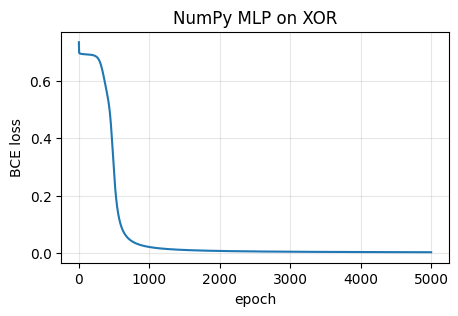

예측 확률:
 [[0.002]
 [0.997]
 [0.998]
 [0.002]]


In [5]:
lr, epochs = 1.0, 5000
W0, b0, W1, b1 = [p.copy() for p in (W0, b0, W1, b1)]   # 초기값 복사
hist = []
for ep in range(epochs):
    Z1, H1, Z2, Y_hat = forward(X, W0, b0, W1, b1)
    L = bce(Y, Y_hat); hist.append(L)
    dW0, db0, dW1, db1 = backward(X, Y, Z1, H1, Z2, Y_hat, W1)
    W0 -= lr * dW0; b0 -= lr * db0; W1 -= lr * dW1; b1 -= lr * db1
    if ep % 1000 == 0 or ep == epochs - 1:
        print(f"epoch {ep:5d}  loss = {L:.4f}")

plt.figure(figsize=(5, 3)); plt.plot(hist); plt.xlabel("epoch"); plt.ylabel("BCE loss"); plt.title("NumPy MLP on XOR"); plt.grid(alpha=.3); plt.show()
print("예측 확률:\n", np.round(forward(X, W0, b0, W1, b1)[-1], 3))

# 2. `nn.Module`로 XOR 학습하기 (PyTorch 표준 방식)

실무에서는 층·손실·최적화기를 직접 구현하지 않고 `torch.nn` / `torch.optim` 모듈을 사용한다.

- **`nn.Linear(2, 2)`**: $\mathbf{W}^{(0)}\mathbf{x} + \mathbf{b}^{(0)}$ 를 수행하는 완전연결층
- **`nn.BCEWithLogitsLoss`**: 시그모이드 + BCE를 **수치적으로 안정하게** 결합한 손실 (출력층에 시그모이드를 따로 두지 않는다)
- **`torch.optim.SGD / Adam`**: 가중치 갱신 규칙
- 학습 루프의 4단계: `optimizer.zero_grad()` → `loss.backward()` → `optimizer.step()` 그리고 순전파

Sequential(
  (0): Linear(in_features=2, out_features=2, bias=True)
  (1): Sigmoid()
  (2): Linear(in_features=2, out_features=1, bias=True)
)
학습 파라미터 수: 9


예측 확률: [0.001 0.999 0.999 0.001]  → 예측 클래스: [0, 1, 1, 0]


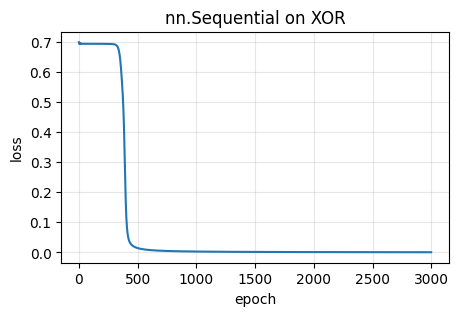

In [6]:
set_seed(2)
model = nn.Sequential(
    nn.Linear(2, 2),   # 입력층 → 은닉층 (노드 2개)
    nn.Sigmoid(),      # 은닉층 활성화 함수 (비선형성이 없으면 MLP도 직선 하나와 같다!)
    nn.Linear(2, 1),   # 은닉층 → 출력층 (로짓 z)
)
print(model)
print("학습 파라미터 수:", sum(p.numel() for p in model.parameters()))

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.5, momentum=0.9)

losses = []
for epoch in range(3000):
    logits = model(Xt)                 # 1) 순전파
    loss = criterion(logits, Yt)       # 2) 손실 계산
    optimizer.zero_grad()              # 3) 이전 기울기 초기화
    loss.backward()                    # 4) 오차 역전파
    optimizer.step()                   # 5) 가중치 갱신
    losses.append(loss.item())

with torch.no_grad():
    probs = torch.sigmoid(model(Xt))
print("예측 확률:", probs.squeeze().numpy().round(3), " → 예측 클래스:", (probs > 0.5).int().squeeze().tolist())
plt.figure(figsize=(5, 3)); plt.plot(losses); plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("nn.Sequential on XOR"); plt.grid(alpha=.3); plt.show()

## 결정 경계(Decision Boundary) 시각화

은닉 노드 2개가 각각 하나의 직선을 만들고, 출력층이 두 직선을 결합해 **비선형 결정 경계**를 만든다.

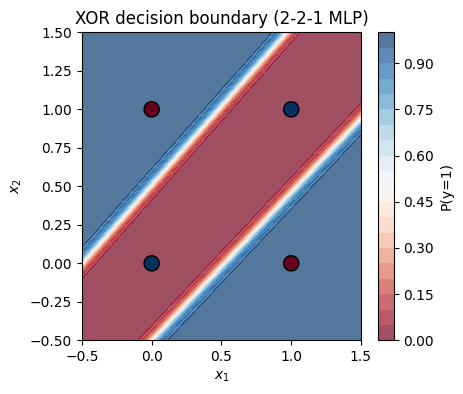

In [7]:
def plot_decision_boundary(model, title):
    xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    with torch.no_grad():
        zz = torch.sigmoid(model(grid)).numpy().reshape(xx.shape)
    plt.figure(figsize=(4.5, 4))
    plt.contourf(xx, yy, zz, levels=20, cmap="RdBu", alpha=.7); plt.colorbar(label="P(y=1)")
    plt.scatter(X[:, 0], X[:, 1], c=Y.ravel(), cmap="RdBu_r", edgecolors="k", s=120)
    plt.title(title); plt.xlabel("$x_1$"); plt.ylabel("$x_2$"); plt.show()

plot_decision_boundary(model, "XOR decision boundary (2-2-1 MLP)")

# 3. (심화) 초기화 · 활성화 함수 · 최적화 기법 비교

같은 구조라도 **초기화, 활성화 함수, 최적화기**에 따라 수렴 속도와 성공률이 크게 달라진다. 아래 실험은 은닉 노드를 4개로 늘리고 10개의 시드로 반복해 **성공률(정확도 100% 도달 비율)** 과 평균 손실 곡선을 비교한다.

Sigmoid + SGD(0.5)               성공률 = 50%, 최종 평균 손실 = 0.3988


Sigmoid + Xavier + SGD(0.5)      성공률 = 100%, 최종 평균 손실 = 0.0801


ReLU + He + SGD(0.5)             성공률 = 60%, 최종 평균 손실 = 0.2020


ReLU + He + Adam(0.05)           성공률 = 50%, 최종 평균 손실 = 0.2344


GELU + He + AdamW(0.05)          성공률 = 100%, 최종 평균 손실 = 0.0002


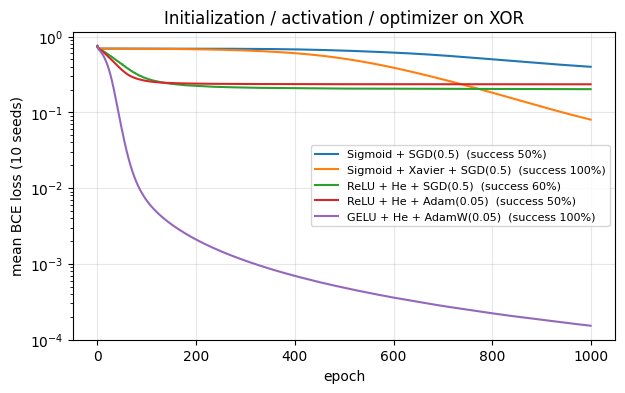

In [8]:
def make_model(act, hidden=4, init="default"):
    m = nn.Sequential(nn.Linear(2, hidden), act, nn.Linear(hidden, 1))
    if init == "he":      # He(Kaiming) 초기화: ReLU 계열에 권장
        for layer in m:
            if isinstance(layer, nn.Linear):
                nn.init.kaiming_normal_(layer.weight, nonlinearity="relu"); nn.init.zeros_(layer.bias)
    elif init == "xavier":  # Xavier(Glorot) 초기화: sigmoid/tanh 계열에 권장
        for layer in m:
            if isinstance(layer, nn.Linear):
                nn.init.xavier_uniform_(layer.weight); nn.init.zeros_(layer.bias)
    return m

def run(cfg, seeds=range(10), epochs=1000):
    curves, success = [], 0
    for s in seeds:
        set_seed(s)
        m = make_model(cfg["act"](), init=cfg["init"])
        opt = cfg["opt"](m.parameters())
        hist = []
        for _ in range(epochs):
            loss = criterion(m(Xt), Yt); opt.zero_grad(); loss.backward(); opt.step(); hist.append(loss.item())
        with torch.no_grad():
            success += int(((torch.sigmoid(m(Xt)) > .5).float() == Yt).all())
        curves.append(hist)
    return np.mean(curves, 0), success / len(seeds)

configs = {
    "Sigmoid + SGD(0.5)":            dict(act=nn.Sigmoid, init="default", opt=lambda p: torch.optim.SGD(p, lr=0.5)),
    "Sigmoid + Xavier + SGD(0.5)":   dict(act=nn.Sigmoid, init="xavier",  opt=lambda p: torch.optim.SGD(p, lr=0.5)),
    "ReLU + He + SGD(0.5)":          dict(act=nn.ReLU,    init="he",      opt=lambda p: torch.optim.SGD(p, lr=0.5)),
    "ReLU + He + Adam(0.05)":        dict(act=nn.ReLU,    init="he",      opt=lambda p: torch.optim.Adam(p, lr=0.05)),
    "GELU + He + AdamW(0.05)":       dict(act=nn.GELU,    init="he",      opt=lambda p: torch.optim.AdamW(p, lr=0.05, weight_decay=1e-4)),
}
plt.figure(figsize=(7, 4))
for name, cfg in configs.items():
    curve, rate = run(cfg)
    plt.plot(curve, label=f"{name}  (success {rate:.0%})")
    print(f"{name:32s} 성공률 = {rate:.0%}, 최종 평균 손실 = {curve[-1]:.4f}")
plt.xlabel("epoch"); plt.ylabel("mean BCE loss (10 seeds)"); plt.yscale("log"); plt.legend(fontsize=8); plt.grid(alpha=.3)
plt.title("Initialization / activation / optimizer on XOR"); plt.show()

## 정리 및 생각해 볼 문제

1. **비선형 활성화 함수**가 없다면 `nn.Linear` 두 개를 쌓아도 결국 하나의 선형 변환이다. 직접 `nn.Sigmoid()`를 제거하고 실행해 확인해 보자.
2. 손으로 계산한 기울기와 `autograd` 결과가 일치했다. 은닉층을 하나 더 추가(2-2-2-1)해도 `backward()` 함수를 확장해 같은 검증을 해 보자.
3. 시그모이드 + 기본 초기화가 자주 실패하는 이유(포화 영역, 기울기 소실)를 슬라이드의 $\sigma'(z)$ 그래프와 연결해 설명해 보자.
4. `lr`을 0.05, 5.0 으로 바꾸면 어떤 현상이 나타나는가? (학습률과 발산·정체의 관계)
5. 은닉 노드가 4개뿐인 이 작은 문제에서는 ReLU가 시드에 따라 실패하기도 한다. 실패한 시드의 은닉 출력을 찍어 보면 항상 0을 내는 노드(**dying ReLU**)가 있는지 확인해 보고, GELU/LeakyReLU가 이를 어떻게 완화하는지 설명해 보자. `hidden=16`으로 늘리면 결과가 어떻게 달라지는가?
